# Multi-armed bandits: implementation

The ten-armed testbed with every selection rule and update the chapter describes (sample averages, constant step size,
optimistic initial values, upper confidence bound, gradient bandit), checked against the true best arm and compared on one scale.
Companion to the chapter note: [Multi-armed bandits](../chapters/02%20Multi-armed%20bandits.md).

**Sections**
1. The testbed and what is the best possible
2. Incremental averages
3. Greedy and epsilon-greedy selection
4. A nonstationary task and a constant step size
5. Optimistic initial values
6. Upper confidence bound selection
7. Gradient bandit and the reward baseline
8. A parameter study
9. Checkpoints

**Not implemented.** Associative search (the chapter's last topic: one set of estimates per situation, chosen by a clue) gets no algorithm or experiment in the chapter beyond its description, and it only repeats the methods below once per situation.
The step-size convergence conditions are statements about infinite sequences of steps, which no finite run can verify; the notebook only uses the $1/k$ and constant step sizes they discuss.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

SEED_TESTBED, SEED_INCR, SEED_EPS, SEED_NONSTAT, SEED_OPT, SEED_UCB, SEED_GRAD, SEED_STUDY = 1, 2, 3, 4, 5, 6, 7, 8  # one seed per section
N_ARMS = 10
N_TASKS = 2000
N_STEPS = 1000
EPSILONS = (0.0, 0.01, 0.1)
ALPHA = 0.1  # constant step size of the nonstationary and optimistic-start comparisons
OPTIMISTIC_Q0 = 5.0
UCB_C = 2.0
SHIFT = 4.0  # mean of the true values in the shifted testbed
WALK_SD = 0.01  # per-step standard deviation of the true values in the nonstationary task
N_STEPS_NONSTAT, N_TASKS_NONSTAT = 10_000, 1000
N_STEPS_LONG, N_TASKS_LONG = 30_000, 1000  # longer horizon for the epsilon comparison
TIE_NOISE = 1e-9  # random tie-breaking: far below any difference between estimates, so it only decides exact ties
STUDY_GRID = {
    "epsilon-greedy": ("epsilon", 2.0 ** np.arange(-7, -1)),
    "gradient bandit": ("alpha", 2.0 ** np.arange(-5, 3)),
    "UCB": ("c", 2.0 ** np.arange(-4, 3)),
    "optimistic greedy": ("Q_1", 2.0 ** np.arange(-2, 3)),
}

## 1. The testbed and what is the best possible

A bandit task has $n$ arms (actions). Arm $a$ has a true value $q(a)$, the mean of the reward it pays, and the reward at step $t$ is
$R_t = q(A_t) + \text{noise}$ with standard normal noise. The learner sees only $R_t$ of the arm it chose.
The testbed is a set of such tasks, each with its true values drawn from a standard normal distribution; results are averaged over the tasks.

- The truth available only to us: the best arm $\operatorname{argmax}_a q(a)$ of each task and the best possible average reward, the mean over tasks of $\max_a q(a)$.
- Two numbers judge a method at each step: the average reward, and the share of tasks in which it chose the best arm (the optimal-action rate).
- The notebook uses `N_TASKS` = 2000 tasks of `N_STEPS` = 1000 steps, the chapter's size. Methods compared within a section run on the same tasks (the same true values, and in the nonstationary section the same drift); only the reward noise and the methods' own random choices are drawn separately.

In [2]:
rng = np.random.default_rng(SEED_TESTBED)
q_testbed = rng.normal(size=(N_TASKS, N_ARMS))
best_possible = q_testbed.max(axis=1).mean()
best_possible_se = q_testbed.max(axis=1).std(ddof=1) / np.sqrt(N_TASKS)
random_play = q_testbed.mean()
print(f"Best possible average reward on {N_TASKS} tasks: {best_possible:.3f} (standard error {best_possible_se:.3f})")
print(f"Average reward of choosing arms at random: {random_play:.3f}")
print(f"Share of arms that are best in their task: {(q_testbed == q_testbed.max(axis=1, keepdims=True)).mean():.3f} (a single best arm per task: 1/{N_ARMS})")
print("Checkpoint: the best possible reward is within 3 standard errors of the known value of E[max of 10 standard normals] (1.539):", abs(best_possible - 1.539) < 3 * best_possible_se)

Best possible average reward on 2000 tasks: 1.533 (standard error 0.013)
Average reward of choosing arms at random: -0.011
Share of arms that are best in their task: 0.100 (a single best arm per task: 1/10)
Checkpoint: the best possible reward is within 3 standard errors of the known value of E[max of 10 standard normals] (1.539): True


### Reading the result

- The best possible average reward on these 2000 tasks is 1.533 (standard error 0.013), consistent with the known expected maximum of ten standard normal values, 1.539. It is the ceiling every later method is judged against.
- The chapter quotes about 1.55 for its own draw of 2000 tasks. That is within about 1.3 standard errors of 1.533 and a little above 1.539, so the difference is sampling noise, not a different testbed (noise in the rewards has mean 0 and does not raise the ceiling).
- Picking arms at random earns -0.011 on average, essentially the mean of the true values (0). Every task has exactly one best arm, so a random choice finds it with probability 0.100.

## 2. Incremental averages

A sample average $Q_t(a)$ is the mean of the rewards received from arm $a$ so far, with a default $Q_1(a) = 0$ before the first pull.
Storing all rewards is unnecessary: with $Q_k$ the average after $k-1$ rewards, the $k$th reward $R_k$ updates it in constant work.

$$
Q_{k+1} = Q_k + \frac{1}{k}\big[R_k - Q_k\big]
$$

The general shape is $\text{NewEstimate} \leftarrow \text{OldEstimate} + \text{StepSize}\,[\text{Target} - \text{OldEstimate}]$; here the target is the reward and the step size is $1/k$.
For a nonstationary task the shrinking $1/k$ is replaced by a constant step size $\alpha \in (0, 1]$:

$$
Q_{k+1} = Q_k + \alpha\big[R_k - Q_k\big] = (1-\alpha)^k Q_1 + \sum_{i=1}^{k} \alpha (1-\alpha)^{k-i} R_i
$$

- The right-hand form is an exponential recency-weighted average: reward $R_i$ gets weight $\alpha(1-\alpha)^{k-i}$, which decays with how many rewards ago it arrived, and the weights (with the one on $Q_1$) sum to 1.
- Both claims are checked below against a direct computation.

In [3]:
def incremental_average(rewards: np.ndarray, q1: float = 0.0, alpha: float | None = None) -> float:
    """Estimate after folding in `rewards` one by one; step size 1/k unless a constant `alpha` is given."""
    q = q1
    for k, r in enumerate(rewards, start=1):
        q += (1 / k if alpha is None else alpha) * (r - q)
    return q


def recency_weights(k: int, alpha: float) -> tuple[float, np.ndarray]:
    """Weight on Q_1 and on rewards R_1..R_k in the constant-step average."""
    return (1 - alpha) ** k, alpha * (1 - alpha) ** (k - np.arange(1, k + 1))

In [4]:
rng = np.random.default_rng(SEED_INCR)
rewards = rng.normal(loc=1.0, size=50)
q1, alpha_check = 7.0, 0.3
gap_avg = abs(incremental_average(rewards, q1=q1) - rewards.mean())
w_q1, w_r = recency_weights(len(rewards), alpha_check)
gap_const = abs(incremental_average(rewards, q1=q1, alpha=alpha_check) - (w_q1 * q1 + w_r @ rewards))
print(f"Incremental 1/k update vs plain mean of 50 rewards (starting estimate {q1}): difference {gap_avg:.2e}")
print(f"Constant step {alpha_check}: update vs closed-form weighted sum: difference {gap_const:.2e}")
print(f"Weights sum to {w_q1 + w_r.sum():.6f}; newest reward weighs {w_r[-1]:.3f}, the one 5 rewards before it {w_r[-6]:.3f}, the starting estimate {w_q1:.1e}")
print("Checkpoint: both updates equal their direct formulas:", gap_avg < 1e-12 and gap_const < 1e-12)

Incremental 1/k update vs plain mean of 50 rewards (starting estimate 7.0): difference 2.22e-16
Constant step 0.3: update vs closed-form weighted sum: difference 2.22e-16
Weights sum to 1.000000; newest reward weighs 0.300, the one 5 rewards before it 0.050, the starting estimate 1.8e-08
Checkpoint: both updates equal their direct formulas: True


### Reading the result

- Both identities hold to rounding error (differences of 2.22e-16): the $1/k$ update with a starting estimate of 7.0 gives exactly the plain mean, so the starting value is forgotten after the first reward; the constant-step update gives exactly the weighted sum.
- With $\alpha = 0.3$ and 50 rewards the newest reward weighs 0.300, the one five rewards earlier 0.050, and the starting estimate 1.8e-08. The weights sum to 1.000000.

## 3. Greedy and epsilon-greedy selection

The greedy rule picks an action with the highest current estimate, breaking ties at random: $A_t = \operatorname{argmax}_a Q_t(a)$.
Choosing the arm that currently looks best is exploiting what is known; choosing any other arm is exploring, which improves that arm's estimate. Greedy never explores, so it never rechecks an apparently worse arm. The $\varepsilon$-greedy rule is greedy except that with probability $\varepsilon$
it picks uniformly among all arms whatever the estimates, so every arm is sampled again and again.

- The value-based methods of this and the next three sections run through one function that handles all tasks at once; each call is one method on one set of tasks. The gradient bandit gets its own function later.
- Values here are sample averages ($1/k$ step size, $Q_1(a) = 0$), as in the chapter's first comparison.
- Random draws per step, in order: tie-breaking noise, exploration coin, random arm, reward noise. The nonstationary task of the next section also lets the true values drift; those increments come from a separate generator so that every method sees the same drift.
- With probability $\varepsilon$ the random pick is uniform over all $n$ arms, so even once the best arm is known it is chosen with probability at most $1 - \varepsilon + \varepsilon/n$ (0.91 for $\varepsilon = 0.1$ and $n = 10$).

In [5]:
def run_value_method(q: np.ndarray, steps: int, rng: np.random.Generator, eps: float = 0.0, alpha: float | None = None,
                     q1: float = 0.0, c: float | None = None, walk_sd: float = 0.0, walk_seed: int = 0) -> tuple[np.ndarray, np.ndarray]:
    """Run an action-value method on every task of `q` (tasks x arms) at once.

    Selection is greedy, epsilon-greedy (`eps`) or upper confidence bound (`c`); the update is the sample average,
    or a constant step `alpha`; `q1` is the initial estimate; `walk_sd` makes the true values drift, drawn from a generator seeded by `walk_seed`
    (the same seed gives every method the same drift).
    Returns rewards and optimal-action indicators, both of shape (steps, tasks).
    """
    q = q.copy()
    n_tasks, n_arms = q.shape
    walk_rng = np.random.default_rng([walk_seed, 1])
    rows = np.arange(n_tasks)
    Q = np.full(q.shape, q1)
    N = np.zeros(q.shape)
    rewards, optimal = np.empty((steps, n_tasks)), np.empty((steps, n_tasks), dtype=bool)
    for t in range(1, steps + 1):
        tie = rng.random(q.shape)
        if c is None:
            score = Q + TIE_NOISE * tie
        else:  # an arm never tried counts as maximizing; the 1e3 puts all of them above every bound
            score = np.where(N == 0, 1e3 + tie, Q + c * np.sqrt(np.log(t) / np.maximum(N, 1)) + TIE_NOISE * tie)
        a = score.argmax(axis=1)
        if eps > 0:
            a = np.where(rng.random(n_tasks) < eps, rng.integers(n_arms, size=n_tasks), a)
        r = q[rows, a] + rng.standard_normal(n_tasks)
        rewards[t - 1], optimal[t - 1] = r, a == q.argmax(axis=1)
        N[rows, a] += 1
        Q[rows, a] += (1 / N[rows, a] if alpha is None else alpha) * (r - Q[rows, a])
        if walk_sd > 0:
            q += walk_rng.normal(scale=walk_sd, size=q.shape)
    return rewards, optimal


def curve_plot(ax, curves: dict, ylabel: str, title: str, scale: float = 1.0) -> None:
    for label, y in curves.items():
        ax.plot(np.arange(1, len(y) + 1), y * scale, label=label, lw=1)
    ax.set(xlabel="steps", ylabel=ylabel, title=title)
    ax.legend()

epsilon 0.0  : average reward over steps 1-100 0.959, over steps 901-1000 1.030; best arm chosen in 34.9% of tasks at the end
epsilon 0.01 : average reward over steps 1-100 0.979, over steps 901-1000 1.296; best arm chosen in 59.4% of tasks at the end
epsilon 0.1  : average reward over steps 1-100 1.008, over steps 901-1000 1.363; best arm chosen in 79.8% of tasks at the end
Best possible average reward: 1.533
Average reward over steps 1-10: epsilon 0.0: 0.576, epsilon 0.01: 0.585, epsilon 0.1: 0.546
  greedy minus epsilon 0.01: -0.009 (standard error of the paired difference 0.020)
  greedy minus epsilon 0.1: +0.029 (standard error of the paired difference 0.020)
Checkpoint: epsilon 0.1 beats epsilon 0.01 over steps 1-100, and both beat greedy over steps 901-1000: True
Checkpoint: greedy finds the best arm in about a third of the tasks: True


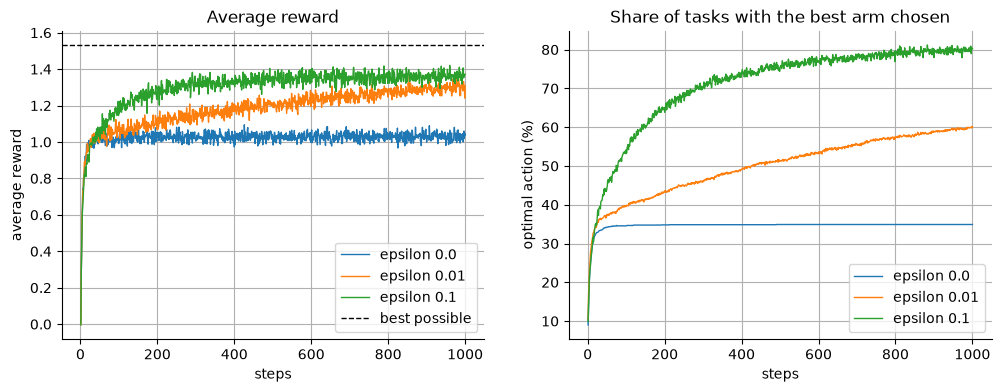

In [6]:
rng = np.random.default_rng(SEED_EPS)
runs_eps = {eps: run_value_method(q_testbed, N_STEPS, rng, eps=eps) for eps in EPSILONS}
rate_final = {eps: o[-100:].mean() for eps, (_, o) in runs_eps.items()}
reward_final = {eps: r[-100:].mean() for eps, (r, _) in runs_eps.items()}
reward_early = {eps: r[:100].mean() for eps, (r, _) in runs_eps.items()}
for eps in EPSILONS:
    print(f"epsilon {eps:<5}: average reward over steps 1-100 {reward_early[eps]:.3f}, over steps 901-1000 {reward_final[eps]:.3f}; best arm chosen in {rate_final[eps]:.1%} of tasks at the end")
print(f"Best possible average reward: {best_possible:.3f}")
first10 = {e: runs_eps[e][0][:10].mean(axis=0) for e in EPSILONS}  # per task, so differences are paired across the shared tasks
print("Average reward over steps 1-10: " + ", ".join(f"epsilon {e}: {first10[e].mean():.3f}" for e in EPSILONS))
for e in (0.01, 0.1):
    d = first10[0.0] - first10[e]
    print(f"  greedy minus epsilon {e}: {d.mean():+.3f} (standard error of the paired difference {d.std(ddof=1) / np.sqrt(N_TASKS):.3f})")
print("Checkpoint: epsilon 0.1 beats epsilon 0.01 over steps 1-100, and both beat greedy over steps 901-1000:",
      reward_early[0.1] > reward_early[0.01] and min(reward_final[0.01], reward_final[0.1]) > reward_final[0.0])
print("Checkpoint: greedy finds the best arm in about a third of the tasks:", 0.25 < rate_final[0.0] < 0.45)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
curve_plot(axes[0], {f"epsilon {e}": r.mean(axis=1) for e, (r, _) in runs_eps.items()}, "average reward", "Average reward")
axes[0].axhline(best_possible, color="k", ls="--", lw=1, label="best possible")
axes[0].legend()
curve_plot(axes[1], {f"epsilon {e}": o.mean(axis=1) for e, (_, o) in runs_eps.items()}, "optimal action (%)", "Share of tasks with the best arm chosen", scale=100)
plt.show()

The chapter says epsilon 0.01 eventually beats epsilon 0.1 on both measures. Within 1000 steps it does not, so the same two settings are run for much longer
(fewer tasks, `N_STEPS_LONG` steps) to see whether and when they cross.

In [7]:
q_long = rng.normal(size=(N_TASKS_LONG, N_ARMS))
long_runs = {eps: run_value_method(q_long, N_STEPS_LONG, rng, eps=eps) for eps in (0.01, 0.1)}
long_reward = {eps: r.mean(axis=1) for eps, (r, _) in long_runs.items()}
long_rate = {eps: o.mean(axis=1) for eps, (_, o) in long_runs.items()}


def last_lead_step(ahead: np.ndarray, behind: np.ndarray, window: int = 100) -> int:
    """End step of the last 100-step window in which `ahead` has a higher average than `behind`."""
    kernel = np.ones(window) / window
    lead = np.convolve(ahead, kernel, mode="valid") > np.convolve(behind, kernel, mode="valid")
    return int(np.flatnonzero(lead).max()) + window


cross_reward = last_lead_step(long_reward[0.1], long_reward[0.01])
cross_rate = last_lead_step(long_rate[0.1], long_rate[0.01])
for eps in (0.01, 0.1):
    print(f"epsilon {eps}: reward over the last 1000 of {N_STEPS_LONG} steps {long_reward[eps][-1000:].mean():.3f}; best arm chosen {long_rate[eps][-1000:].mean():.1%}")
print(f"Best possible average reward on these {N_TASKS_LONG} tasks: {q_long.max(axis=1).mean():.3f}")
print(f"Epsilon 0.1 last leads (100-step windows) at step {cross_reward} on reward and at step {cross_rate} on optimal-action rate")
print(f"Checkpoint: after {N_STEPS_LONG} steps epsilon 0.01 is ahead on reward and on optimal-action rate:",
      long_reward[0.01][-1000:].mean() > long_reward[0.1][-1000:].mean() and long_rate[0.01][-1000:].mean() > long_rate[0.1][-1000:].mean())

epsilon 0.01: reward over the last 1000 of 30000 steps 1.546; best arm chosen 92.0%
epsilon 0.1: reward over the last 1000 of 30000 steps 1.407; best arm chosen 89.7%
Best possible average reward on these 1000 tasks: 1.565
Epsilon 0.1 last leads (100-step windows) at step 1434 on reward and at step 13792 on optimal-action rate
Checkpoint: after 30000 steps epsilon 0.01 is ahead on reward and on optimal-action rate: True


### Reading the result

- The left plot has the best possible reward (1.533) as a dashed line. Greedy plateaus at an average reward of 1.030 over steps 901-1000 and has the best arm in 34.9% of tasks, about the one-third the chapter reports. In the other tasks its first samples of the best arm disappointed and it never went back.
- Epsilon 0.1 explores more and leads early (average reward 1.008 over steps 1-100, against 0.979 for epsilon 0.01 and 0.959 for greedy). At the end of the 1000 steps it chooses the best arm in 79.8% of tasks, still rising, with the 91% ceiling of the earlier bullet not yet in reach.
- Within 1000 steps epsilon 0.01 is slower: 1.296 reward and 59.4% best-arm choices over steps 901-1000, against 1.363 and 79.8% for epsilon 0.1. This matches the chapter's figure but not yet its statement that epsilon 0.01 eventually does better.
- The long run settles that. After 30000 steps epsilon 0.01 earns 1.546 against 1.407 for epsilon 0.1 (best possible on these tasks: 1.565) and chooses the best arm 92.0% of the time against 89.7%, so epsilon 0.1 stays under its 91% ceiling. Epsilon 0.1 last leads on reward around step 1434 and on best-arm rate around step 13792. These are rough single-run values: "last step ahead" read off noisy 100-step windows is biased toward late steps. The chapter's statement holds, but only far beyond the 1000 steps of its figure.
- Over the first 10 steps greedy earns 0.576, epsilon 0.01 0.585 and epsilon 0.1 0.546. Paired across the shared tasks, greedy minus epsilon 0.01 is -0.009 and greedy minus epsilon 0.1 is +0.029, each with a standard error of 0.020: neither difference clearly exceeds its noise. The notebook therefore does not reproduce the chapter's slightly faster start for greedy, but it cannot rule out a small one.

## 4. A nonstationary task and a constant step size

In a nonstationary task the true values change over time. Averages that weigh every reward equally keep trusting old rewards;
a constant step size $\alpha$ lets old rewards fade (the recency weights of the incremental-averages section).
The chapter describes this without a testbed; here all true values start at 0 in every task and then at every step each value changes by an independent normal increment of standard deviation `WALK_SD` (a random walk),
so the best arm changes over time (a choice of this notebook; both methods see the same drift), for `N_STEPS_NONSTAT` = 10,000 steps over `N_TASKS_NONSTAT` = 1000 tasks. Both methods use $\varepsilon = 0.1$; the constant step is $\alpha = 0.1$.
Truth: at each step the best arm and best reward are those of the current true values.

sample average (1/k)  : reward over steps 9501-10000 1.111; best arm chosen in 47.6% (standard error 1.3%)
constant step 0.1     : reward over steps 9501-10000 1.369; best arm chosen in 78.0% (standard error 0.6%)
Over the first 500 steps: sample average 20.7%, constant step 22.2% best arm chosen
Checkpoint: late in the run the constant step finds the best arm more often than the sample average: True


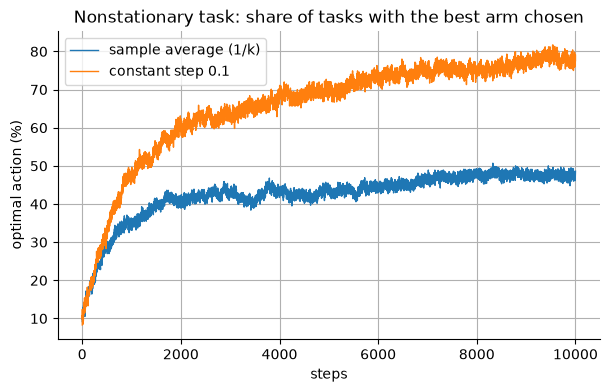

In [8]:
rng = np.random.default_rng([SEED_NONSTAT, 0])
q_start = np.zeros((N_TASKS_NONSTAT, N_ARMS))
runs_ns = {
    "sample average (1/k)": run_value_method(q_start, N_STEPS_NONSTAT, rng, eps=0.1, walk_sd=WALK_SD, walk_seed=SEED_NONSTAT),
    f"constant step {ALPHA}": run_value_method(q_start, N_STEPS_NONSTAT, rng, eps=0.1, alpha=ALPHA, walk_sd=WALK_SD, walk_seed=SEED_NONSTAT),
}
last = slice(-500, None)
for label, (r, o) in runs_ns.items():
    per_task = o[last].mean(axis=0)
    print(f"{label:<22}: reward over steps {N_STEPS_NONSTAT - 499}-{N_STEPS_NONSTAT} {r[last].mean():.3f}; best arm chosen in {o[last].mean():.1%} (standard error {per_task.std(ddof=1) / np.sqrt(len(per_task)):.1%})")
print(f"Over the first 500 steps: sample average {runs_ns['sample average (1/k)'][1][:500].mean():.1%}, constant step {runs_ns[f'constant step {ALPHA}'][1][:500].mean():.1%} best arm chosen")
print("Checkpoint: late in the run the constant step finds the best arm more often than the sample average:",
      runs_ns[f"constant step {ALPHA}"][1][last].mean() > runs_ns["sample average (1/k)"][1][last].mean())

fig, ax = plt.subplots()
curve_plot(ax, {k: o.mean(axis=1) for k, (_, o) in runs_ns.items()}, "optimal action (%)", "Nonstationary task: share of tasks with the best arm chosen", scale=100)
plt.show()

### Reading the result

- Both methods use epsilon 0.1 on the same drifting values. Over steps 9501-10000 the sample average earns 1.111 and chooses the current best arm in 47.6% of tasks (standard error 1.3%); the constant step of 0.1 earns 1.369 and chooses it in 78.0% (standard error 0.6%).
- Early on the two are close (20.7% against 22.2% over the first 500 steps): the sample average adapts well while the values have barely moved, but its steps shrink as counts grow, so once the true values have drifted away from what it averaged it adapts ever more slowly. The plot shows the gap opening over time.
- The chapter argues this in words only, so there is no figure to compare with; the direction agrees with its claim.

## 5. Optimistic initial values

A method is biased by its starting estimates $Q_1(a)$. Starting every estimate at $+5$, far above any plausible reward here, makes whichever arm is tried first pay less than expected,
so the learner moves on to other arms: purely greedy selection ($\varepsilon = 0$) ends up exploring.
The comparison is with a realistic $\varepsilon$-greedy method ($Q_1 = 0$, $\varepsilon = 0.1$); both use the constant step size $\alpha = 0.1$.

Best arm chosen over steps 1-20: optimistic 13.2%, realistic 26.5%
Last step at which optimistic is not ahead of realistic: 158 (a single-run value on noisy curves, so rough)
Best arm chosen by optimistic at steps 10 / 11 / 12: 10.5% / 42.4% / 25.4%
Best arm chosen over steps 901-1000: optimistic 86.0%, realistic 75.3%
Checkpoint: optimistic is behind early (steps 1-20) and ahead late: True


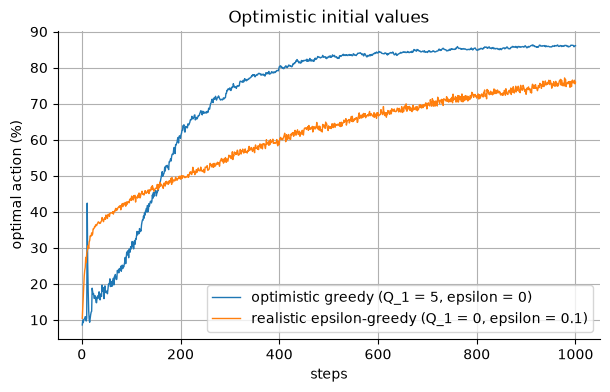

In [9]:
rng = np.random.default_rng(SEED_OPT)
q_opt = rng.normal(size=(N_TASKS, N_ARMS))
runs_opt = {
    "optimistic greedy (Q_1 = 5, epsilon = 0)": run_value_method(q_opt, N_STEPS, rng, alpha=ALPHA, q1=OPTIMISTIC_Q0),
    "realistic epsilon-greedy (Q_1 = 0, epsilon = 0.1)": run_value_method(q_opt, N_STEPS, rng, eps=0.1, alpha=ALPHA),
}
opt_rate, real_rate = (runs_opt[k][1].mean(axis=1) for k in runs_opt)
crossing = int(np.flatnonzero(opt_rate <= real_rate).max()) + 2
print(f"Best arm chosen over steps 1-20: optimistic {opt_rate[:20].mean():.1%}, realistic {real_rate[:20].mean():.1%}")
print(f"Last step at which optimistic is not ahead of realistic: {crossing - 1} (a single-run value on noisy curves, so rough)")
print(f"Best arm chosen by optimistic at steps 10 / 11 / 12: {opt_rate[9]:.1%} / {opt_rate[10]:.1%} / {opt_rate[11]:.1%}")
print(f"Best arm chosen over steps 901-1000: optimistic {opt_rate[-100:].mean():.1%}, realistic {real_rate[-100:].mean():.1%}")
print("Checkpoint: optimistic is behind early (steps 1-20) and ahead late:", opt_rate[:20].mean() < real_rate[:20].mean() and opt_rate[-100:].mean() > real_rate[-100:].mean())

fig, ax = plt.subplots()
curve_plot(ax, {k: o.mean(axis=1) for k, (_, o) in runs_opt.items()}, "optimal action (%)", "Optimistic initial values", scale=100)
plt.show()

### Reading the result

- Optimistic greedy starts worse: over steps 1-20 it chooses the best arm in 13.2% of tasks against 26.5% for epsilon-greedy. The last step at which it is not ahead is 158 (a rough single-run value, late-biased on noisy curves; the chapter's figure crosses at about step 150 by eye), and over steps 901-1000 it chooses the best arm in 86.0% against 75.3%. Both agree with the chapter: worse at first, better later.
- The plot shows a spike near step 11: the best arm is chosen in 42.4% of tasks at step 11, against 10.5% at step 10 and 25.4% at step 12. A likely explanation, not checked by a cell: after the first ten pulls every estimate has dropped below 5 by an amount that grows with the reward received, so at step 11 the arm that paid most looks best, and it is often the best arm. The spike fades as the optimism wears off, the temporary drive to explore the chapter describes.

## 6. Upper confidence bound selection

Epsilon-greedy explores blindly. Better to explore arms in proportion to their chance of being best, counting both how close their estimate is to the top and how uncertain it is.
Upper confidence bound (UCB) selection adds an uncertainty bonus to each estimate:

$$
A_t = \operatorname*{argmax}_a \left[ Q_t(a) + c \sqrt{\frac{\ln t}{N_t(a)}} \right]
$$

- $N_t(a)$ is how often arm $a$ was chosen before step $t$ and $c > 0$ sets the degree of exploration; an arm with $N_t(a) = 0$ counts as maximizing.
- Each pull of $a$ shrinks its bonus; each pull of another arm grows it slowly, through the logarithm, so every arm is eventually chosen but poorer or well-sampled ones less often.
- Compared with $\varepsilon$-greedy at $\varepsilon = 0.1$, both with sample-average estimates.

Average reward at steps 1-10: UCB -0.000, epsilon-greedy 0.540
Average reward at step 10 / 11 / 12: UCB 0.019 / 1.074 / 0.941; epsilon-greedy 0.803 / 0.839 / 0.814
Average reward over steps 101-1000: UCB 1.458, epsilon-greedy 1.351
Best arm chosen at the end: UCB 85.6%, epsilon-greedy 78.8%
Checkpoint: UCB makes a spike at step 11 (above steps 10 and 12) and beats epsilon-greedy over steps 101-1000: True


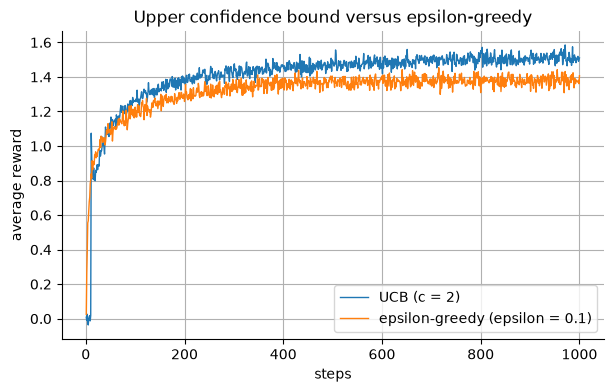

In [10]:
rng = np.random.default_rng(SEED_UCB)
q_ucb = rng.normal(size=(N_TASKS, N_ARMS))
runs_ucb = {
    f"UCB (c = {UCB_C:g})": run_value_method(q_ucb, N_STEPS, rng, c=UCB_C),
    "epsilon-greedy (epsilon = 0.1)": run_value_method(q_ucb, N_STEPS, rng, eps=0.1),
}
ucb_r, eg_r = (runs_ucb[k][0].mean(axis=1) for k in runs_ucb)
print(f"Average reward at steps 1-10: UCB {ucb_r[:10].mean():.3f}, epsilon-greedy {eg_r[:10].mean():.3f}")
print(f"Average reward at step 10 / 11 / 12: UCB {ucb_r[9]:.3f} / {ucb_r[10]:.3f} / {ucb_r[11]:.3f}; epsilon-greedy {eg_r[9]:.3f} / {eg_r[10]:.3f} / {eg_r[11]:.3f}")
print(f"Average reward over steps 101-1000: UCB {ucb_r[100:].mean():.3f}, epsilon-greedy {eg_r[100:].mean():.3f}")
print(f"Best arm chosen at the end: UCB {runs_ucb[f'UCB (c = {UCB_C:g})'][1][-100:].mean():.1%}, epsilon-greedy {runs_ucb['epsilon-greedy (epsilon = 0.1)'][1][-100:].mean():.1%}")
print("Checkpoint: UCB makes a spike at step 11 (above steps 10 and 12) and beats epsilon-greedy over steps 101-1000:", ucb_r[10] > max(ucb_r[9], ucb_r[11]) and ucb_r[100:].mean() > eg_r[100:].mean())

fig, ax = plt.subplots()
curve_plot(ax, {k: r.mean(axis=1) for k, (r, _) in runs_ucb.items()}, "average reward", "Upper confidence bound versus epsilon-greedy")
plt.show()

### Reading the result

- UCB earns -0.000 on average over the first 10 steps because it first tries each arm once, in random order (epsilon-greedy: 0.540). At step 11 it jumps to 1.074, above step 10 (0.019) and step 12 (0.941), while epsilon-greedy stays near 0.8 (0.803, 0.839, 0.814).
- The step-11 spike has a simple cause: every arm has been tried once, so all bonuses are equal and UCB picks the arm with the highest sample reward, which is often a good one. At step 12 the arm just pulled has a smaller bonus and exploration resumes.
- Afterwards UCB is better: 1.458 over steps 101-1000 against 1.351, and 85.6% best-arm choices at the end against 78.8%. This agrees with the chapter's figure, including the initial dip and the spike.

## 7. Gradient bandit and the reward baseline

Instead of values, the gradient bandit learns a numerical preference $H_t(a)$ per arm. Only differences matter: a soft-max turns preferences into probabilities,

$$
\pi_t(a) = \Pr\{A_t = a\} = \frac{e^{H_t(a)}}{\sum_{b=1}^{n} e^{H_t(b)}},
$$

starting from $H_1(a) = 0$ for all arms (equal probabilities). After choosing $A_t$ and receiving $R_t$, all preferences move at once:

$$
H_{t+1}(a) = H_t(a) + \alpha\,(R_t - \bar R_t)\,(\mathbb{I}_{a=A_t} - \pi_t(a))
$$

- $\mathbb{I}_{a=A_t}$ is 1 for the chosen arm and 0 otherwise; this one line covers both cases of the chapter's update: chosen arm $+\alpha(R_t-\bar R_t)(1-\pi_t(A_t))$, others $-\alpha(R_t-\bar R_t)\pi_t(a)$.
- $\bar R_t$ is the average of all rewards up to and including step $t$, the baseline: a reward above it makes the chosen arm more likely, a reward below makes it less likely.
- On average the update equals gradient ascent on the expected reward $\sum_b \pi_t(b) q(b)$; any baseline that does not depend on the chosen arm leaves that average unchanged but changes the variance of the update.

Experiment: the testbed shifted so that true values have mean $+4$ (unit spread as before). The baseline adapts to the new level at once; without it ($\bar R_t = 0$) every reward looks "above baseline".

In [11]:
def sample_softmax(H: np.ndarray, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
    """Soft-max probabilities of each row of preferences `H` and one arm drawn from each."""
    pi = np.exp(H - H.max(axis=1, keepdims=True))
    pi /= pi.sum(axis=1, keepdims=True)
    a = np.minimum((rng.random((len(H), 1)) > pi.cumsum(axis=1)).sum(axis=1), H.shape[1] - 1)
    return pi, a


def gradient_step(H: np.ndarray, pi: np.ndarray, a: np.ndarray, r: np.ndarray, baseline: np.ndarray, alpha: float) -> np.ndarray:
    """New preferences after choosing arms `a` (probabilities `pi`) and receiving rewards `r`, one row per task."""
    chosen = np.zeros(H.shape)
    chosen[np.arange(len(H)), a] = 1
    return H + alpha * (r - baseline)[:, None] * (chosen - pi)


def run_gradient(q: np.ndarray, steps: int, rng: np.random.Generator, alpha: float, baseline: bool = True) -> tuple[np.ndarray, np.ndarray]:
    """Gradient bandit on every task of `q` at once; the baseline is the running average of all rewards, or 0.
    Returns rewards and optimal-action indicators, both of shape (steps, tasks).
    """
    n_tasks = len(q)
    H, avg, best = np.zeros(q.shape), np.zeros(n_tasks), q.argmax(axis=1)
    rewards, optimal = np.empty((steps, n_tasks)), np.empty((steps, n_tasks), dtype=bool)
    for t in range(1, steps + 1):
        pi, a = sample_softmax(H, rng)
        r = q[np.arange(n_tasks), a] + rng.standard_normal(n_tasks)
        rewards[t - 1], optimal[t - 1] = r, a == best
        avg += (r - avg) / t
        H = gradient_step(H, pi, a, r, avg if baseline else np.zeros(n_tasks), alpha)
    return rewards, optimal

Hand case (3 arms, equal preferences, arm 0 chosen, reward 2, baseline 0.5, alpha 0.5): preferences change by [ 0.5  -0.25 -0.25]; by hand +0.5, -0.25, -0.25
Baseline +0: largest gap between the mean change over 200000 steps and the exact gradient 0.0022, largest gap in standard errors 1.71
Baseline +5: largest gap between the mean change over 200000 steps and the exact gradient 0.0035, largest gap in standard errors 0.95
Baseline -3: largest gap between the mean change over 200000 steps and the exact gradient 0.0045, largest gap in standard errors 1.77
Checkpoint: the update in the gradient bandit code matches the hand case: True
Checkpoint: its mean change is the exact gradient of expected reward for any baseline (within 4.5 standard errors): True
alpha = 0.1, with baseline  : best arm chosen in 84.7% of tasks over steps 901-1000, average reward 5.327
alpha = 0.4, with baseline  : best arm chosen in 72.7% of tasks over steps 901-1000, average reward 5.359
alpha = 0.1, without baselin

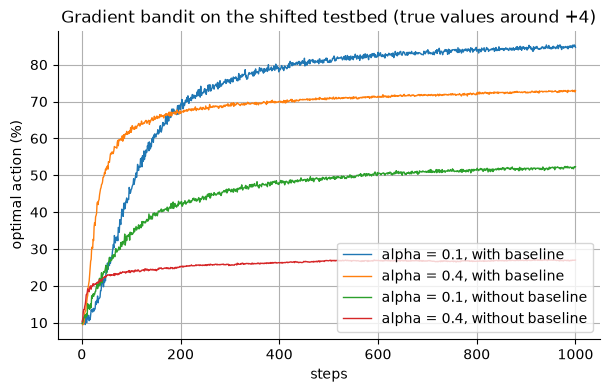

In [12]:
rng = np.random.default_rng(SEED_GRAD)
hand = gradient_step(np.zeros((1, 3)), np.full((1, 3), 1 / 3), np.array([0]), np.array([2.0]), np.array([0.5]), alpha=0.5)
print(f"Hand case (3 arms, equal preferences, arm 0 chosen, reward 2, baseline 0.5, alpha 0.5): preferences change by {np.round(hand[0], 4)}; by hand +0.5, -0.25, -0.25")

M = 200_000  # copies of one task, each taking one step from the same preferences
H_one, q_one = rng.normal(size=N_ARMS), rng.normal(size=N_ARMS)
pi_one = np.exp(H_one) / np.exp(H_one).sum()
exact_gradient = pi_one * (q_one - pi_one @ q_one)
z_scores = []
for b in (0.0, 5.0, -3.0):
    pi, a = sample_softmax(np.tile(H_one, (M, 1)), rng)
    change = gradient_step(np.tile(H_one, (M, 1)), pi, a, q_one[a] + rng.standard_normal(M), np.full(M, b), alpha=1.0) - H_one
    z_scores.append(np.abs(change.mean(axis=0) - exact_gradient) / (change.std(axis=0, ddof=1) / np.sqrt(M)))
    print(f"Baseline {b:+.0f}: largest gap between the mean change over {M} steps and the exact gradient {np.abs(change.mean(axis=0) - exact_gradient).max():.4f}, "
          f"largest gap in standard errors {z_scores[-1].max():.2f}")
print("Checkpoint: the update in the gradient bandit code matches the hand case:", np.allclose(hand, [[0.5, -0.25, -0.25]]))
print("Checkpoint: its mean change is the exact gradient of expected reward for any baseline (within 4.5 standard errors):", max(z.max() for z in z_scores) < 4.5)

q_shift = rng.normal(loc=SHIFT, size=(N_TASKS, N_ARMS))
runs_grad = {
    f"alpha = {a}, {'with' if base else 'without'} baseline": run_gradient(q_shift, N_STEPS, rng, a, base)
    for base in (True, False) for a in (0.1, 0.4)
}
for label, (r, o) in runs_grad.items():
    print(f"{label:<28}: best arm chosen in {o[-100:].mean():.1%} of tasks over steps 901-1000, average reward {r.mean():.3f}")
print(f"Best possible average reward on the shifted testbed: {q_shift.max(axis=1).mean():.3f}")
gap = runs_grad["alpha = 0.4, with baseline"][0].mean(axis=0) - runs_grad["alpha = 0.1, with baseline"][0].mean(axis=0)
print(f"With baseline, average reward of alpha 0.4 minus alpha 0.1: {gap.mean():+.3f} (standard error of the paired difference {gap.std(ddof=1) / np.sqrt(N_TASKS):.3f})")
print("Checkpoint: for both step sizes the baseline gives more optimal choices at the end:",
      all(runs_grad[f"alpha = {a}, with baseline"][1][-100:].mean() > runs_grad[f"alpha = {a}, without baseline"][1][-100:].mean() for a in (0.1, 0.4)))

fig, ax = plt.subplots()
curve_plot(ax, {k: o.mean(axis=1) for k, (_, o) in runs_grad.items()}, "optimal action (%)", "Gradient bandit on the shifted testbed (true values around +4)", scale=100)
plt.show()

### Reading the result

- The update used by the gradient bandit code reproduces the hand-computed case (chosen arm +0.5, others -0.25). Averaged over 200000 simulated steps from the same preferences, its change equals the exact gradient of the expected reward for baselines 0, 5 and -3: the largest gaps are 0.0022, 0.0035 and 0.0045, at most 1.77 standard errors, well inside the 4.5 allowed.
- The chapter further states that a baseline changes only the variance of the update, not its expected value, and that the running average adapts at once to a shifted reward level. The check above covers the expectation part; the variance and adaptation claims are the chapter's and are tested here only through the experiment below.
- On the testbed shifted to +4 the best possible average reward is 5.515. With the baseline, $\alpha = 0.1$ chooses the best arm in 84.7% of tasks over steps 901-1000 and $\alpha = 0.4$ in 72.7%; without it 51.9% and 26.9%. The baseline helps clearly for both step sizes, at about the levels read by eye from the chapter's figure (85%, 73%, 50%, 28%). The plot shows all four curves.
- Without the baseline the reference level is 0 while the true values are around +4, so most rewards count as "better than expected" whichever arm was chosen, which is why the choices stick early (the chapter's explanation; this notebook shows the outcome, not the mechanism).
- With the baseline the larger step has a slightly higher average reward over all 1000 steps (+0.032 against $\alpha = 0.1$, paired standard error 0.006) but the lower best-arm share at the end, so it learns faster and settles on a worse arm more often.

## 8. A parameter study

Each method has a parameter, so comparing methods means comparing them over their parameters.
Instead of a learning curve per setting, one number summarizes a whole curve: the average reward over the first 1000 steps.
Each method is run over its parameter on a log scale (factors of two) on the same tasks, in the ranges of the chapter's study:
$\varepsilon$ for $\varepsilon$-greedy (sample averages), $\alpha$ for the gradient bandit (with baseline), $c$ for UCB, and the initial value $Q_1$ for greedy with optimistic starts and $\alpha = 0.1$.

In [13]:
def study_run(method: str, value: float, q: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Average reward over all steps, one entry per task, for `method` at parameter `value`."""
    if method == "epsilon-greedy":
        r, _ = run_value_method(q, N_STEPS, rng, eps=value)
    elif method == "gradient bandit":
        r, _ = run_gradient(q, N_STEPS, rng, alpha=value)
    elif method == "UCB":
        r, _ = run_value_method(q, N_STEPS, rng, c=value)
    else:
        r, _ = run_value_method(q, N_STEPS, rng, alpha=ALPHA, q1=value)
    return r.mean(axis=0)

epsilon-greedy    : best 1.324 at epsilon = 0.0625 (standard error 0.012); worst setting in the grid 1.116
gradient bandit   : best 1.397 at alpha = 0.25 (standard error 0.013); worst setting in the grid 0.962
UCB               : best 1.478 at c = 1 (standard error 0.013); worst setting in the grid 1.165
optimistic greedy : best 1.451 at Q_1 = 1 (standard error 0.013); worst setting in the grid 1.325
Best possible average reward on these tasks: 1.537
epsilon-greedy    : settings within 0.05 of the best span a factor 4 in epsilon; within 0.1, a factor 8
gradient bandit   : settings within 0.05 of the best span a factor 4 in alpha; within 0.1, a factor 4
UCB               : settings within 0.05 of the best span a factor 8 in c; within 0.1, a factor 32
optimistic greedy : settings within 0.05 of the best span a factor 2 in Q_1; within 0.1, a factor 4
UCB minus epsilon-greedy at their best settings: +0.155 (standard error of the paired difference 0.004)
UCB minus gradient bandit at their b

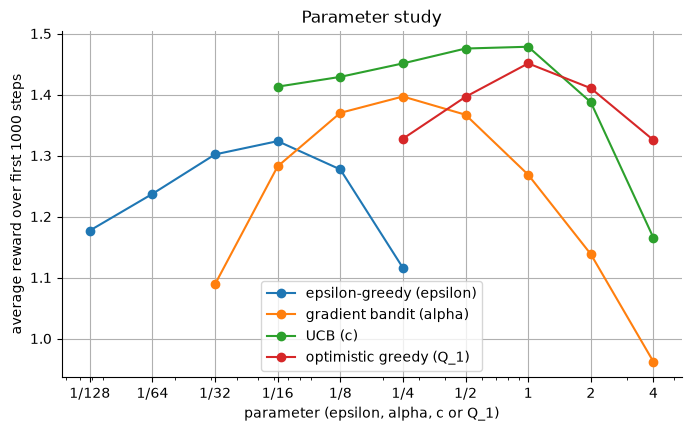

In [14]:
rng = np.random.default_rng(SEED_STUDY)
q_study = rng.normal(size=(N_TASKS, N_ARMS))
study = {m: [study_run(m, v, q_study, rng) for v in grid] for m, (_, grid) in STUDY_GRID.items()}
mean_reward = {m: np.array([x.mean() for x in xs]) for m, xs in study.items()}
se_reward = {m: np.array([x.std(ddof=1) / np.sqrt(len(x)) for x in xs]) for m, xs in study.items()}
best_study = q_study.max(axis=1).mean()
for m, (name, grid) in STUDY_GRID.items():
    k = int(mean_reward[m].argmax())
    print(f"{m:<18}: best {mean_reward[m][k]:.3f} at {name} = {grid[k]:g} (standard error {se_reward[m][k]:.3f}); worst setting in the grid {mean_reward[m].min():.3f}")
print(f"Best possible average reward on these tasks: {best_study:.3f}")
for m, (name, grid) in STUDY_GRID.items():
    spans = [grid[mean_reward[m] > mean_reward[m].max() - thr] for thr in (0.05, 0.1)]
    print(f"{m:<18}: settings within 0.05 of the best span a factor {spans[0].max() / spans[0].min():g} in {name}; within 0.1, a factor {spans[1].max() / spans[1].min():g}")
best_task = {m: study[m][int(mean_reward[m].argmax())] for m in study}  # per-task rewards at each method's best setting, on shared tasks
z_vs_ucb = {}
for m in ("epsilon-greedy", "gradient bandit", "optimistic greedy"):
    d = best_task["UCB"] - best_task[m]
    z_vs_ucb[m] = d.mean() / (d.std(ddof=1) / np.sqrt(N_TASKS))
    print(f"UCB minus {m} at their best settings: {d.mean():+.3f} (standard error of the paired difference {d.std(ddof=1) / np.sqrt(N_TASKS):.3f})")
print("Checkpoint: every method peaks inside its grid (inverted U):", all(0 < mean_reward[m].argmax() < len(mean_reward[m]) - 1 for m in study))

fig, ax = plt.subplots(figsize=(8, 4.5))
for m, (name, grid) in STUDY_GRID.items():
    ax.plot(grid, mean_reward[m], marker="o", label=f"{m} ({name})")
ax.set(xscale="log", xlabel="parameter (epsilon, alpha, c or Q_1)", ylabel="average reward over first 1000 steps", title="Parameter study")
ax.set_xticks([2.0**k for k in range(-7, 3)], [f"1/{2**-k}" if k < 0 else str(2**k) for k in range(-7, 3)])
ax.legend()
plt.show()

### Reading the result

- Best settings (average reward over the first 1000 steps, best possible 1.537): UCB 1.478 at $c = 1$, optimistic greedy 1.451 at $Q_1 = 1$, gradient bandit 1.397 at $\alpha = 0.25$, epsilon-greedy 1.324 at $\varepsilon = 0.0625$ (standard errors 0.012-0.013). All four peaks sit inside their grids (the inverted U in the plot), and their locations match the chapter's figure by eye.
- UCB is ahead of the others at their best settings on the same tasks: by 0.155 over epsilon-greedy and 0.082 over the gradient bandit (paired standard error 0.004 each), and by 0.027 over optimistic greedy (paired standard error 0.003). The paired standard errors only cover the noise within this set of tasks, so the notebook asserts the two large margins and treats the small one as supporting the chapter's "UCB seems best" without proving it.
- Sensitivity, with the arbitrary threshold stated: settings within 0.05 of a method's best average reward span a factor of 4 (epsilon-greedy), 4 (gradient bandit), 8 (UCB) and 2 (optimistic greedy) in the parameter; within 0.1 they span 8, 4, 32 and 4. The chapter says methods do well over about an order of magnitude. With the 0.05 threshold the notebook's ranges are narrower (2 to 8 times), with 0.1 they are as wide or wider, so the notebook supports "fairly insensitive" only loosely and the answer depends on the threshold and the grid.
- This ranking holds for this family of tasks only (normal values and normal noise) and for a 1000-step horizon.

## 9. Checkpoints

The best possible reward differs slightly between rows below because each section draws its own tasks.

In [15]:
def final_100(run: tuple[np.ndarray, np.ndarray]) -> tuple[float, float]:
    return float(run[0][-100:].mean()), float(run[1][-100:].mean())

In [16]:
rows = [
    ("greedy (epsilon 0)", runs_eps[0.0], q_testbed),
    ("epsilon-greedy, epsilon 0.01", runs_eps[0.01], q_testbed),
    ("epsilon-greedy, epsilon 0.1", runs_eps[0.1], q_testbed),
    ("optimistic greedy, Q_1 = 5", runs_opt["optimistic greedy (Q_1 = 5, epsilon = 0)"], q_opt),
    ("epsilon-greedy, constant step", runs_opt["realistic epsilon-greedy (Q_1 = 0, epsilon = 0.1)"], q_opt),
    ("UCB, c = 2", runs_ucb["UCB (c = 2)"], q_ucb),
    ("gradient bandit, alpha 0.1, baseline (+4 testbed)", runs_grad["alpha = 0.1, with baseline"], q_shift),
    ("gradient bandit, alpha 0.1, no baseline (+4 testbed)", runs_grad["alpha = 0.1, without baseline"], q_shift),
]
checks = [
    ("the best possible reward matches the known 1.539 within 3 standard errors", abs(best_possible - 1.539) < 3 * best_possible_se),
    ("incremental updates equal the plain mean and the weighted sum", gap_avg < 1e-12 and gap_const < 1e-12),
    ("greedy plateaus near 1 and finds the best arm in about a third of the tasks", reward_final[0.0] < 1.1 and 0.25 < rate_final[0.0] < 0.45),
    ("within 1000 steps epsilon 0.1 leads epsilon 0.01 early, and both beat greedy late", reward_early[0.1] > reward_early[0.01] and min(reward_final[0.01], reward_final[0.1]) > reward_final[0.0]),
    ("in the long run epsilon 0.1 stays below the 91% ceiling of optimal choices", long_rate[0.1][-1000:].mean() < 0.91),
    ("epsilon 0.01 overtakes epsilon 0.1 on reward and optimal-action rate in the long run", long_reward[0.01][-1000:].mean() > long_reward[0.1][-1000:].mean() and long_rate[0.01][-1000:].mean() > long_rate[0.1][-1000:].mean()),
    ("a constant step tracks the best arm better than sample averages in the drifting task", runs_ns[f"constant step {ALPHA}"][1][last].mean() > runs_ns["sample average (1/k)"][1][last].mean() + 0.1),
    ("optimistic greedy is behind epsilon-greedy early and ahead late", opt_rate[:20].mean() < real_rate[:20].mean() and opt_rate[-100:].mean() > real_rate[-100:].mean()),
    ("UCB spikes at step 11 and beats epsilon-greedy afterwards", ucb_r[10] > max(ucb_r[9], ucb_r[11]) and ucb_r[100:].mean() > eg_r[100:].mean()),
    ("the gradient bandit's own update reproduces a hand-computed case", np.allclose(hand, [[0.5, -0.25, -0.25]])),
    ("its mean change equals the exact gradient of expected reward for baselines 0, 5 and -3", max(z.max() for z in z_scores) < 4.5),
    ("with the baseline the gradient bandit finds the best arm more often on the +4 testbed", all(runs_grad[f"alpha = {a}, with baseline"][1][-100:].mean() > runs_grad[f"alpha = {a}, without baseline"][1][-100:].mean() + 0.2 for a in (0.1, 0.4))),
    ("every method peaks inside its parameter grid", all(0 < mean_reward[m].argmax() < len(mean_reward[m]) - 1 for m in study)),
    ("UCB beats epsilon-greedy and the gradient bandit at their best settings by more than 3 paired standard errors", z_vs_ucb["epsilon-greedy"] > 3 and z_vs_ucb["gradient bandit"] > 3),
    ("sanity: no method's average reward exceeds the best possible reward", all(mean_reward[m].max() < best_study for m in study)),
]

In [17]:
for claim, ok in checks:
    print(("PASS " if ok else "FAIL ") + claim)
assert all(ok for _, ok in checks)

print(f"\n{'method (last 100 of 1000 steps)':<54}{'reward':>8}{'best arm':>10}{'best possible':>15}")
for name, run, q in rows:
    reward, rate = final_100(run)
    print(f"{name:<54}{reward:>8.3f}{rate:>10.1%}{q.max(axis=1).mean():>15.3f}")

PASS the best possible reward matches the known 1.539 within 3 standard errors
PASS incremental updates equal the plain mean and the weighted sum
PASS greedy plateaus near 1 and finds the best arm in about a third of the tasks
PASS within 1000 steps epsilon 0.1 leads epsilon 0.01 early, and both beat greedy late
PASS in the long run epsilon 0.1 stays below the 91% ceiling of optimal choices
PASS epsilon 0.01 overtakes epsilon 0.1 on reward and optimal-action rate in the long run
PASS a constant step tracks the best arm better than sample averages in the drifting task
PASS optimistic greedy is behind epsilon-greedy early and ahead late
PASS UCB spikes at step 11 and beats epsilon-greedy afterwards
PASS the gradient bandit's own update reproduces a hand-computed case
PASS its mean change equals the exact gradient of expected reward for baselines 0, 5 and -3
PASS with the baseline the gradient bandit finds the best arm more often on the +4 testbed
PASS every method peaks inside its parame